Device: cuda


100.0%


Training images: 50000
Testing images: 10000


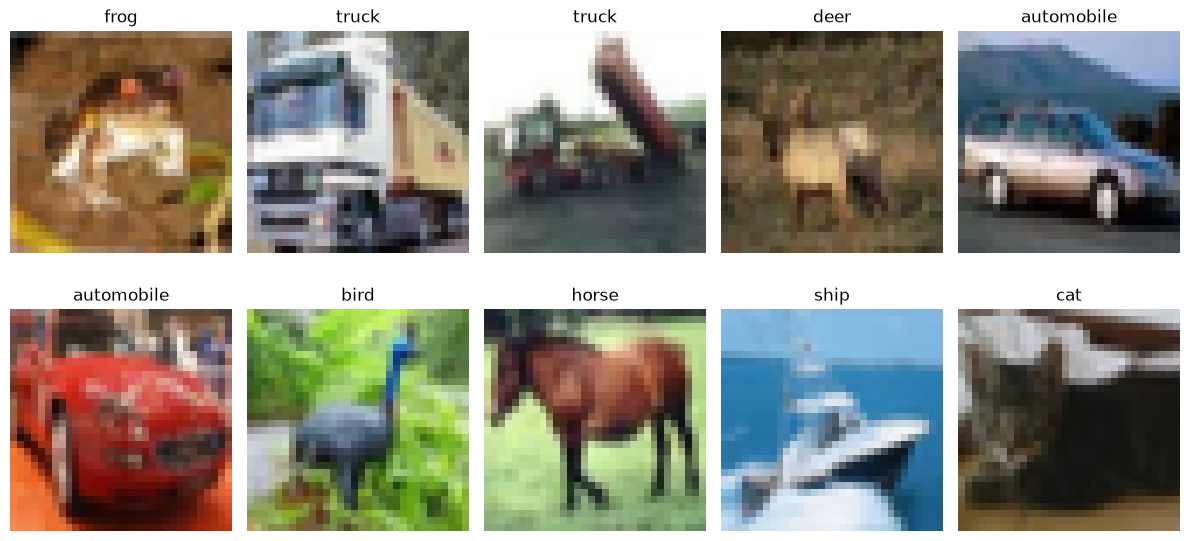


Class distribution:
airplane: 5000
automobile: 5000
bird: 5000
cat: 5000
deer: 5000
dog: 5000
frog: 5000
horse: 5000
ship: 5000
truck: 5000

Batch image shape: torch.Size([128, 3, 32, 32])
Batch label shape: torch.Size([128])

Basic neural network:
BasicNN(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (layers): Sequential(
    (0): Linear(in_features=3072, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=10, bias=True)
  )
)

CNN:
CNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1,

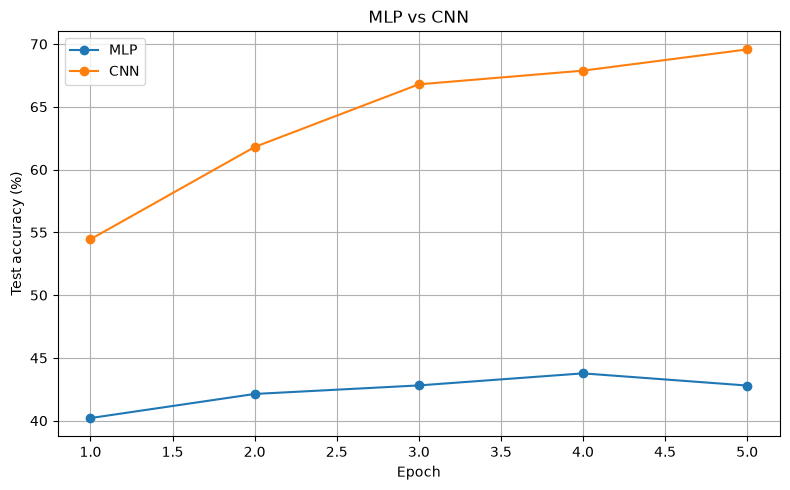

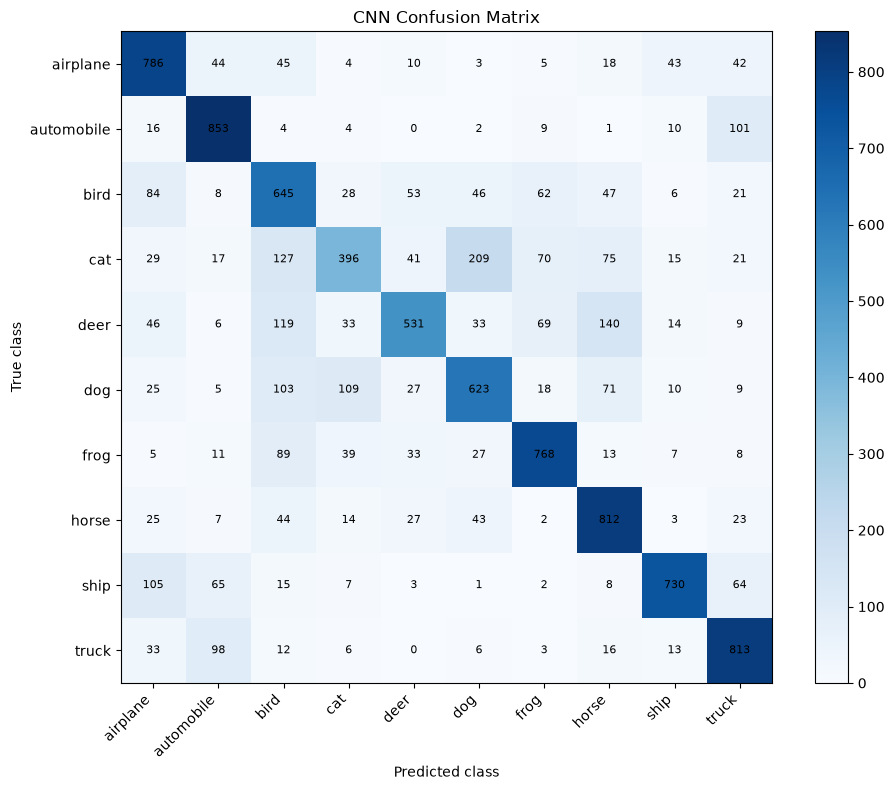

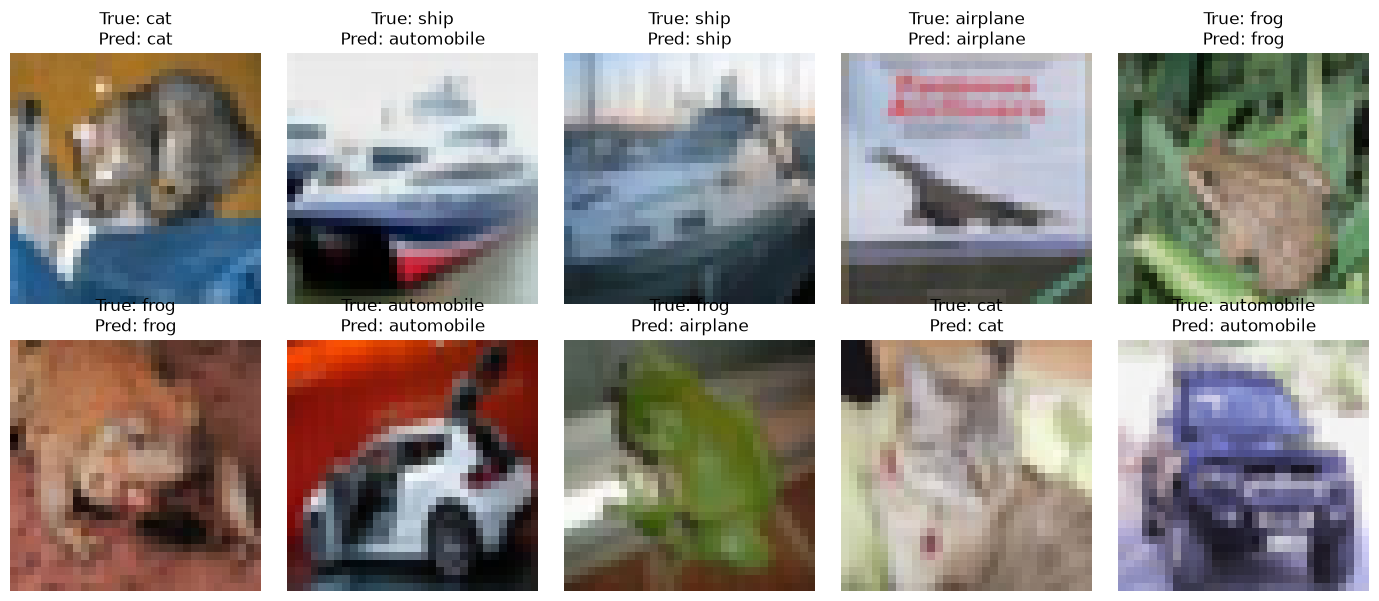


Saved cifar10_mlp.pth and cifar10_cnn.pth


In [ ]:

# ============================================================
# CIFAR-10 MULTI-CLASS IMAGE CLASSIFICATION
# Basic Neural Network (MLP) vs Convolutional Neural Network
# ============================================================

# STEP 1: IMPORT LIBRARIES
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torchvision
import torchvision.transforms as transforms

from torch import nn
from torch.utils.data import DataLoader
import torch.optim as optim


# Reproducibility (results can still vary across hardware)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
print("Device:", device)


# STEP 1: DOWNLOAD AND LOAD CIFAR-10
classes = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

# Untransformed dataset for exploration and visualization
raw_train = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True
)

raw_test = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True
)

print("Training images:", len(raw_train))
print("Testing images:", len(raw_test))


# STEP 2: EXPLORE AND VISUALIZE DATA
fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    image, label = raw_train[i]
    ax.imshow(image)
    ax.set_title(classes[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

# Class distribution
labels_array = np.array(raw_train.targets)

print("\nClass distribution:")
for i, name in enumerate(classes):
    print(f"{name}: {np.sum(labels_array == i)}")


# STEP 3: PREPROCESS IMAGES
mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=train_transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=test_transform
)

batch_size = 128

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

images, batch_labels = next(iter(train_loader))
print("\nBatch image shape:", images.shape)
print("Batch label shape:", batch_labels.shape)


# STEP 4: BUILD THE BASIC NEURAL NETWORK
class BasicNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.flatten = nn.Flatten()

        self.layers = nn.Sequential(
            nn.Linear(3 * 32 * 32, 512),
            nn.ReLU(),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Linear(256, 10)
        )

    def forward(self, x):
        return self.layers(self.flatten(x))


# STEP 5: BUILD THE CNN
class CNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 256),
            nn.ReLU(),
            nn.Linear(256, 10)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


mlp = BasicNN().to(device)
cnn = CNN().to(device)

print("\nBasic neural network:")
print(mlp)
print("\nCNN:")
print(cnn)


# STEP 6: LOSS FUNCTION AND OPTIMIZERS
criterion = nn.CrossEntropyLoss()

mlp_optimizer = optim.Adam(
    mlp.parameters(), lr=0.001
)

cnn_optimizer = optim.Adam(
    cnn.parameters(), lr=0.001
)


# STEP 6: TRAINING FUNCTION
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        n = labels.size(0)
        total_loss += loss.item() * n
        correct += (outputs.argmax(1) == labels).sum().item()
        total += n

    return total_loss / total, 100 * correct / total


# STEP 7: EVALUATION FUNCTION
@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        n = labels.size(0)
        total_loss += loss.item() * n
        correct += (outputs.argmax(1) == labels).sum().item()
        total += n

    return total_loss / total, 100 * correct / total


def fit_model(model, optimizer, train_loader, test_loader,
              criterion, device, epochs=5):

    history = {
        "train_loss": [],
        "train_acc": [],
        "test_loss": [],
        "test_acc": []
    }

    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch(
            model, train_loader, criterion, optimizer, device
        )

        # For this beginner experiment, evaluate each epoch.
        # Prefer a separate validation set for model selection.
        test_loss, test_acc = evaluate(
            model, test_loader, criterion, device
        )

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["test_loss"].append(test_loss)
        history["test_acc"].append(test_acc)

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.2f}% | "
            f"Test Loss: {test_loss:.4f} | "
            f"Test Acc: {test_acc:.2f}%"
        )

    return history


# TRAIN BOTH MODELS
EPOCHS = 5

print("\n========== TRAINING MLP ==========")
mlp_history = fit_model(
    mlp, mlp_optimizer, train_loader, test_loader,
    criterion, device, epochs=EPOCHS
)

print("\n========== TRAINING CNN ==========")
cnn_history = fit_model(
    cnn, cnn_optimizer, train_loader, test_loader,
    criterion, device, epochs=EPOCHS
)


# STEP 7: FINAL ACCURACY COMPARISON
mlp_loss, mlp_acc = evaluate(
    mlp, test_loader, criterion, device
)

cnn_loss, cnn_acc = evaluate(
    cnn, test_loader, criterion, device
)

print("\n========== FINAL RESULTS ==========")
print(f"MLP test loss: {mlp_loss:.4f}")
print(f"MLP test accuracy: {mlp_acc:.2f}%")
print(f"CNN test loss: {cnn_loss:.4f}")
print(f"CNN test accuracy: {cnn_acc:.2f}%")

plt.figure(figsize=(8, 5))
epoch_numbers = range(1, EPOCHS + 1)

plt.plot(
    epoch_numbers, mlp_history["test_acc"],
    marker="o", label="MLP"
)
plt.plot(
    epoch_numbers, cnn_history["test_acc"],
    marker="o", label="CNN"
)

plt.xlabel("Epoch")
plt.ylabel("Test accuracy (%)")
plt.title("MLP vs CNN")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# STEP 7: GET CNN PREDICTIONS
@torch.no_grad()
def get_predictions(model, loader, device):
    model.eval()

    all_true = []
    all_pred = []

    for images, labels in loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_true.extend(labels.tolist())
        all_pred.extend(predictions.cpu().tolist())

    return np.array(all_true), np.array(all_pred)


true_labels, predictions = get_predictions(
    cnn, test_loader, device
)


# STEP 7: CONFUSION MATRIX (NO EXTRA LIBRARY REQUIRED)
num_classes = len(classes)

confusion = np.zeros(
    (num_classes, num_classes), dtype=np.int64
)

np.add.at(confusion, (true_labels, predictions), 1)

plt.figure(figsize=(10, 8))
plt.imshow(confusion, cmap="Blues")
plt.colorbar()

plt.xticks(
    range(num_classes), classes, rotation=45, ha="right"
)
plt.yticks(range(num_classes), classes)

plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("CNN Confusion Matrix")

for i in range(num_classes):
    for j in range(num_classes):
        plt.text(
            j, i, str(confusion[i, j]),
            ha="center", va="center", fontsize=8
        )

plt.tight_layout()
plt.show()


# STEP 7: DISPLAY SAMPLE CNN PREDICTIONS
@torch.no_grad()
def show_predictions(model, dataset, device, count=10):
    model.eval()
    count = min(count, len(dataset))

    cols = 5
    rows = (count + cols - 1) // cols

    fig, axes = plt.subplots(
        rows, cols, figsize=(14, 3 * rows), squeeze=False
    )

    mean_tensor = torch.tensor(mean).view(3, 1, 1)
    std_tensor = torch.tensor(std).view(3, 1, 1)

    for i, ax in enumerate(axes.flat):
        if i >= count:
            ax.axis("off")
            continue

        image, true_label = dataset[i]

        output = model(image.unsqueeze(0).to(device))
        predicted_label = output.argmax(dim=1).item()

        # Undo normalization for display only
        display_image = image * std_tensor + mean_tensor
        display_image = display_image.clamp(0, 1)
        display_image = display_image.permute(1, 2, 0)

        ax.imshow(display_image)
        ax.set_title(
            f"True: {classes[true_label]}\n"
            f"Pred: {classes[predicted_label]}"
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()


show_predictions(cnn, test_dataset, device, count=10)


# SAVE TRAINED MODELS
torch.save(mlp.state_dict(), "cifar10_mlp.pth")
torch.save(cnn.state_dict(), "cifar10_cnn.pth")

print("\nSaved cifar10_mlp.pth and cifar10_cnn.pth")
